## Glucose Prediction 


This assignment's focus is on predicting blood glucose. There are four parts to the assignment:


   1. Data cleaning
 
   2. Population level model
 
   3. Improving model training
 
   4. Transfer learning



In [1]:
import warnings
warnings.filterwarnings('ignore')

import sys
import os
from mads.lib.path import assets

data_cleaners = assets.find("shared_files/assignment2/data_cleaners.py")
sys.path.append(os.path.dirname(data_cleaners))
import data_cleaners as dc

find_best_hyperparameters = assets.find("shared_files/assignment2/find_best_hyperparameters.py")
sys.path.append(os.path.dirname(find_best_hyperparameters))
import find_best_hyperparameters as fbh

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = dc.Diabetes()

X = data.X
y = data.y

pid_to_indices = {}
for pid in X['patient_id'].unique().tolist():
    X_df = X[X['patient_id'] == pid]
    pid_to_indices[pid] = X_df.index

splits = dc.TrainSplits(X, y, combine=True, pid_to_indices=pid_to_indices)

## <font color='magenta'>Warm Up</font>

Before you solve this notebook's main task we invite you to do a warmup to take a look at the loss curve. This is ungraded, so feel free to skip if you need.

You will modify `best_lstm_parameters_training_data_return_loss` so that it returns three things:

 - A list of the average training loss for each epoch
 - A list of the average validation loss for each epoch
 - The best LSTM model

For example, the training and validation loss lists should like look the following (Note that the numbers below are just an example)
```python
loss_list = [127.85, 74.22, ... , 68.06, 63.13]
```


You then use the average training losses, and average validation losses to create a plot that shows one line for the validation losses and one for the training losses.

Try setting the hidden size to 64.

## <font color='magenta'>Task One</font>
Does the plot you created suggest overfitting to you? How can you tell. 

You may note that the loss is jumping around after a certain point and has stabilized before we halted training.  


Learning rate scheduler can help us to stop training when our loss has stabilized, and can prevent overfitting. In this task, you will add a learning rate scheduler  to your code. To do so you will complete the function `best_lstm_parameters_training_data_with_lr`.  This function will also need to return the average training loss at each epoch and the average validation loss at each epoch, along with the trained model as we did in the above function. 

For example, the training and validation loss lists should look like the following (Note that numbers below are just an example)
```python
loss_list = [127.85, 74.22, ... , 68.06, 63.13]
```
After implementing these changes we encourage you to plot the losses and see if differences arise. 



In [3]:
training_loss_lr,validation_loss_lr,lstm_model_lr_64 = fbh.best_lstm_parameters_training_data_with_lr(
    splits.train_df_X, 
    splits.train_df_y,
    splits.validate_df_X, 
    splits.validate_df_y, 
    hidden_size = 64)

Hidden layer size: 64


In [4]:
# Hidden test are within this cell


In [5]:
print("Training epochs:", len(training_loss_lr))
print("First five training losses:", training_loss_lr[:5])
print("First five validation losses:", validation_loss_lr[:5])

Training epochs: 50
First five training losses: [127.05431009928385, 71.07578557332357, 67.61473509470622, 52.10698369344075, 47.76847496032715]
First five validation losses: [83.27919387817383, 93.49665069580078, 54.083404541015625, 81.18864059448242, 83.10132217407227]


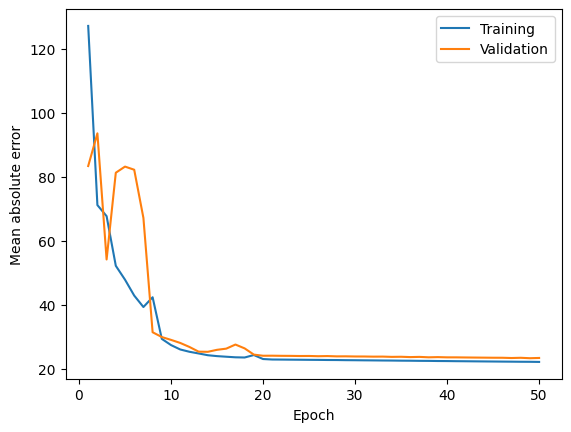

In [6]:
epochs = range(1, len(training_loss_lr) + 1)

plt.plot(epochs, training_loss_lr, label="Training")
plt.plot(epochs, validation_loss_lr, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Mean absolute error")
plt.legend()
plt.show()

## IMPORTANT: Uncomment the following code when you are ready to move on to the next assignment

In [7]:
script = assets.find('copy_shared_files.sh')
!bash {script}

=== Copying shared files back to coursework ===
✅ Shared files successfully copied back to coursework.
